# EVA-X-S on combined dataset (CheXpert + VinDr-CXR)

In [1]:
# Configurations
import os
import sys
import json
import time
import zipfile
import subprocess
from pathlib import Path

START = time.time()
INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
WORK.mkdir(parents=True, exist_ok=True)
ZIP_NAME = 'chexpert_vindr_combined.zip'
ZIP_PATH = ''
PRETRAINED_WEIGHTS = ''
RUN_NAME = 'seed14'
SEED = 14
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.05
LAYER_DECAY = 0.55
MICRO_BATCH = 64
ACCUMULATION = 8
EVAL_BATCH = 64
NUM_WORKERS = 2
THRESHOLD = 0.5
RESUME = True

REPO_COMMIT = 'eedd642c85339b25682ceb574b644cb9afe88e62'
HF_REVISION = '35ddcd6dab6ca99bbdb6cb45c8d1b093aefbd0ee'
REPO = WORK / 'EVA-X-eedd642c'
CODE_DIR = WORK / 'eva_x_official'
RUNTIME = WORK / 'eva_x_combined_runtime.py'
RESULTS = WORK / 'eva_x_s_combined_results' / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
KEYS = ['atelectasis', 'cardiomegaly', 'consolidation', 'pleural_effusion']
TARGETS = ['target_' + key for key in KEYS]
MASKS = ['mask_' + key for key in KEYS]


In [2]:
# Install dependencies and check the Kaggle GPUs
from importlib import metadata
packages = {'timm': '0.9.16', 'einops': '0.8.1', 'huggingface_hub': '0.36.2'}
missing = []
for name, version in packages.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f'{name}=={version}')
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

import gc
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Session options.')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('GPUs:', ', '.join(torch.cuda.get_device_name(i) for i in range(GPU_COUNT)))


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


GPUs: Tesla T4, Tesla T4


In [3]:
# Locate the combined ZIP and validate its split manifests
if ZIP_PATH:
    archive_path = Path(ZIP_PATH)
else:
    candidates = sorted(INPUT.glob('**/' + ZIP_NAME))
    valid_candidates = []
    for candidate in candidates:
        with zipfile.ZipFile(candidate) as probe:
            if any(name.endswith('test/labels.csv') for name in probe.namelist()):
                valid_candidates.append(candidate)
    if len(valid_candidates) != 1:
        raise FileNotFoundError(f'Attach one notebook output containing {ZIP_NAME}, or set ZIP_PATH. Found {len(valid_candidates)} valid archives.')
    archive_path = valid_candidates[0]
if not archive_path.is_file():
    raise FileNotFoundError(archive_path)

with zipfile.ZipFile(archive_path) as archive:
    names = set(archive.namelist())
    found = sorted(name for name in names if name.endswith('test/labels.csv'))
    if len(found) != 1:
        raise ValueError('The ZIP must contain one test/labels.csv.')
    prefix = found[0][:-len('test/labels.csv')]
    settings_path = prefix + 'settings.json'
    if settings_path in names:
        settings = json.loads(archive.read(settings_path))
        if settings.get('labels') != LABELS or settings.get('targets') != TARGETS or settings.get('masks') != MASKS:
            raise ValueError('Unexpected label order in settings.json.')
    splits = {}
    required = {'sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS}
    for split in ['train', 'validation', 'test']:
        manifest = prefix + split + '/labels.csv'
        if manifest not in names:
            raise FileNotFoundError(manifest)
        frame = pd.read_csv(archive.open(manifest))
        if not required.issubset(frame.columns):
            raise ValueError(f'{split} is missing {sorted(required - set(frame.columns))}.')
        if frame.empty or frame['sample_id'].isna().any() or frame['sample_id'].duplicated().any():
            raise ValueError(f'{split} has invalid sample IDs.')
        for column in TARGETS + MASKS:
            frame[column] = pd.to_numeric(frame[column], errors='raise')
            if frame[column].isna().any() or not frame[column].isin([0, 1]).all():
                raise ValueError(f'{split}/{column} must contain only 0 or 1.')
            frame[column] = frame[column].astype(np.uint8)
        frame['zip_image_path'] = frame['image_path'].map(
            lambda path: str(path) if str(path) in names else prefix + str(path).lstrip('/'))
        missing_images = set(frame['zip_image_path']) - names
        if missing_images:
            raise FileNotFoundError(f'{split}: {len(missing_images)} missing images; example {next(iter(missing_images))}')
        if set(frame.source_dataset) != {'chexpert', 'vindr'}:
            raise ValueError(f'{split} must include both source datasets.')
        splits[split] = frame.reset_index(drop=True)

for field in ['sample_id', 'group_id', 'zip_image_path']:
    sets = [set(splits[part][field]) for part in ['train', 'validation', 'test']]
    if sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]:
        raise ValueError(f'{field} overlaps between splits.')
for split, frame in splits.items():
    print(f'{split}: {len(frame):,} images | ' + ', '.join(
        f'{key} {value:,}' for key, value in frame.source_dataset.value_counts().items()))
print('Combined ZIP:', archive_path)


train: 19,973 images | vindr 12,000, chexpert 7,973
validation: 2,526 images | vindr 1,500, chexpert 1,026
test: 2,501 images | vindr 1,500, chexpert 1,001
Combined ZIP: /kaggle/input/notebooks/shadril238/chexpert-vindr-combined-image-dataset/chexpert_vindr_combined.zip


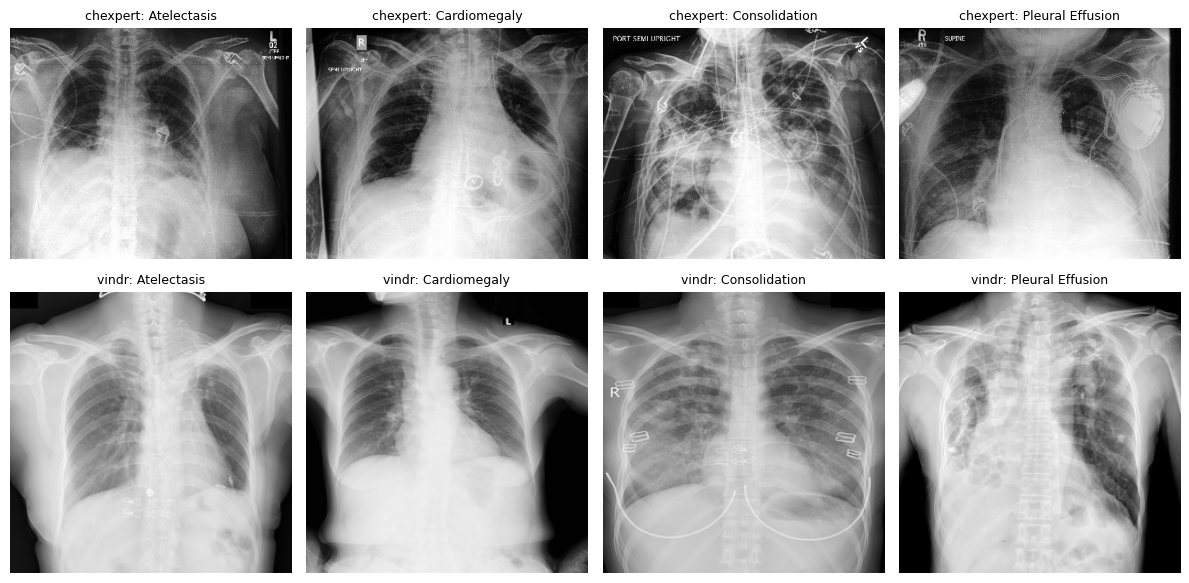

In [4]:
# Display example positive images from both sources
import io
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
with zipfile.ZipFile(archive_path) as archive:
    for row, source_name in enumerate(['chexpert', 'vindr']):
        source_frame = splits['train'].loc[splits['train'].source_dataset.eq(source_name)]
        for column, (label, target, mask) in enumerate(zip(LABELS, TARGETS, MASKS)):
            positives = source_frame.loc[source_frame[mask].eq(1) & source_frame[target].eq(1)]
            ax = axes[row, column]
            if not positives.empty:
                sample = positives.sample(1, random_state=SEED).iloc[0]
                with Image.open(io.BytesIO(archive.read(sample.zip_image_path))) as image:
                    ax.imshow(image.convert('L'), cmap='gray')
            ax.set_title(f'{source_name}: {label}', fontsize=9)
            ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [5]:
# Fetch the pinned official EVA-X architecture
if not (REPO / '.git').exists():
    subprocess.run(['git', 'init', '-q', str(REPO)], check=True)
    subprocess.run(['git', '-C', str(REPO), 'remote', 'add', 'origin', 'https://github.com/hustvl/EVA-X.git'], check=True)
current = subprocess.run(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
if current != REPO_COMMIT:
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', '--depth', '1', 'origin', REPO_COMMIT], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', '--detach', REPO_COMMIT], check=True)
CODE_DIR.mkdir(exist_ok=True)
print('Official source:', REPO_COMMIT[:12])


Official source: eedd642c8533


In [6]:
%%writefile {CODE_DIR / 'kaggle_ops.py'}
# Save the PyTorch equivalents of the official fused operations.
# PyTorch equivalents of the two xFormers operations used by EVA-X-S.
import types
import torch
from torch import nn
from torch.nn import functional as F


class TorchSwiGLU(nn.Module):
    def __init__(self, in_features, hidden_features, out_features=None, bias=True, **kwargs):
        super().__init__()
        out_features = out_features or in_features
        self.w12 = nn.Linear(in_features, 2 * hidden_features, bias=bias)
        self.w3 = nn.Linear(hidden_features, out_features, bias=bias)

    def forward(self, x):
        x1, x2 = self.w12(x).chunk(2, dim=-1)
        return self.w3(F.silu(x1) * x2)


def memory_efficient_attention(q, k, v):
    output = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2),
                                           v.transpose(1, 2), dropout_p=0.)
    return output.transpose(1, 2).contiguous()


xops = types.SimpleNamespace(SwiGLU=TorchSwiGLU, memory_efficient_attention=memory_efficient_attention)


Writing /kaggle/working/eva_x_official/kaggle_ops.py


In [7]:
%%writefile {RUNTIME}
# Save the official-source compatibility helpers.
# Runtime helpers for the official EVA-X-S combined notebook.
import ast
import contextlib
import copy
import hashlib
import importlib.util
import io
import json
import math
import os
import random
import re
import sys
import time
import types
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
TARGETS = ['target_atelectasis', 'target_cardiomegaly', 'target_consolidation', 'target_pleural_effusion']
MASKS = ['mask_atelectasis', 'mask_cardiomegaly', 'mask_consolidation', 'mask_pleural_effusion']
MODEL_NAME = 'eva02_small_patch16_xattn_fusedLN_SwiGLU_preln_RoPE'


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


def prepare_official_code(repo, destination):
    # Keep the authors' architecture; replace only the CUDA kernel dependencies.
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / '__init__.py').write_text('')
    source = (Path(repo) / 'classification/models/models_eva.py').read_text()
    replacements = {
        'import xformers.ops as xops': 'from .kaggle_ops import xops',
        'from apex.normalization import FusedLayerNorm': 'from torch.nn import LayerNorm as FusedLayerNorm',
    }
    for before, after in replacements.items():
        if source.count(before) != 1:
            raise RuntimeError('The pinned EVA-X source does not match the compatibility patch.')
        source = source.replace(before, after)
    (destination / 'models_eva.py').write_text(source)
    (destination / 'rope.py').write_text((Path(repo) / 'classification/models/rope.py').read_text())
    source = (Path(repo) / 'classification/utils/dataloader_med.py').read_text()
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.ClassDef) and n.name == 'CheXpert')
    dataset_source = ast.get_source_segment(source, node)
    # Explicit assignments retain upstream label values with pandas 2/3 Copy-on-Write.
    dataset_source = re.sub(r"self\.df\[col\]\.replace\(([^\n]*?),\s*inplace=True\)",
                            r"self.df[col] = self.df[col].replace(\1)", dataset_source)
    dataset_source = re.sub(r"self\.df\[col\]\.fillna\(([^\n]*?),\s*inplace=True\)",
                            r"self.df[col] = self.df[col].fillna(\1)", dataset_source)
    imports = 'import random\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom PIL import Image\nfrom torch.utils.data import Dataset\n'
    (destination / 'chexpert.py').write_text(imports + dataset_source + '\n')
    (destination / 'lr_decay.py').write_text((Path(repo) / 'classification/utils/lr_decay.py').read_text())
    return {'architecture': 'official source with PyTorch kernel substitutions',
            'dataset': 'official CheXpert class; explicit pandas assignments; unchanged sampling',
            'optimizer_groups': 'official layer-wise decay implementation'}


Writing /kaggle/working/eva_x_combined_runtime.py


In [8]:
%%writefile -a {RUNTIME}
# Define direct ZIP image loading and the EVA-X-S image transform
def image_transform():
    return transforms.Compose([
        transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
        transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize((0.49185243,) * 3, (0.28509309,) * 3),
    ])


def import_official(code_dir):
    code_dir = Path(code_dir)
    sys.path.insert(0, str(code_dir.parent))
    package = code_dir.name
    importlib.import_module(package)
    with contextlib.redirect_stdout(io.StringIO()):
        models = importlib.import_module(package + '.models_eva')
    decay = importlib.import_module(package + '.lr_decay')
    return models, decay


class CombinedImages(Dataset):
    def __init__(self, archive_path, manifest, image_prefix):
        self.archive_path = str(archive_path)
        self.frame = pd.read_csv(manifest)
        self.paths = [str(path) for path in self.frame['zip_image_path']]
        self.targets = self.frame[TARGETS].to_numpy(np.float32)
        self.masks = self.frame[MASKS].to_numpy(np.float32)
        self.prefix = image_prefix
        self.transform = image_transform()
        self.archive = None

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        if self.archive is None:
            self.archive = zipfile.ZipFile(self.archive_path)
        with Image.open(io.BytesIO(self.archive.read(self.paths[index]))) as image:
            x = self.transform(image.convert('RGB'))
        return x, torch.from_numpy(self.targets[index].copy()), torch.from_numpy(self.masks[index].copy())


def make_dataset(cfg, split):
    return CombinedImages(cfg['archive_path'], cfg['manifests'][split], cfg['archive_prefix'])


Appending to /kaggle/working/eva_x_combined_runtime.py


In [9]:
%%writefile -a {RUNTIME}
# Load the official EVA-X-S weights into the four-label model
def make_model(cfg, checkpoint_path, training=False):
    path = Path(checkpoint_path)
    if not path.is_file():
        raise FileNotFoundError(f'Model checkpoint not found: {path}')
    expected_hash = cfg.get('checkpoint_hashes', {}).get(path.name)
    if expected_hash and sha256(path) != expected_hash:
        raise ValueError(f'Checkpoint checksum mismatch: {path}')

    models, _ = import_official(cfg['code_dir'])
    if not hasattr(models, MODEL_NAME):
        raise AttributeError(f'The pinned EVA-X source has no model named {MODEL_NAME}.')
    with contextlib.redirect_stdout(io.StringIO()):
        model = getattr(models, MODEL_NAME)(
            num_classes=len(LABELS), img_size=224, use_mean_pooling=True,
            drop_path_rate=0.15 if training else 0., drop_rate=0.,
            attn_drop_rate=0., use_checkpoint=False, stop_grad_conv1=False)

    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    if not isinstance(checkpoint, dict):
        raise TypeError(f'Checkpoint must contain a state dictionary: {path}')
    if not training and 'label_order' in checkpoint and checkpoint['label_order'] != LABELS:
        raise ValueError('Fine-tuned checkpoint label order does not match the combined dataset.')
    state = checkpoint.get('model', checkpoint.get('module', checkpoint))
    if not isinstance(state, dict):
        raise TypeError(f'Checkpoint model weights are not a dictionary: {path}')
    state = {key.removeprefix('module.'): value for key, value in state.items()}
    model_state = model.state_dict()

    if training:
        for key in ('head.weight', 'head.bias'):
            if key in state and state[key].shape != model_state[key].shape:
                state.pop(key)
        for key in ('mask_token', 'lm_head.weight', 'lm_head.bias',
                    'norm.weight', 'norm.bias'):
            if key not in model_state:
                state.pop(key, None)

    status = model.load_state_dict(state, strict=False)
    allowed_missing = {'head.weight', 'head.bias', 'fc_norm.weight', 'fc_norm.bias'} if training else set()
    unexpected_missing = set(status.missing_keys) - allowed_missing
    if unexpected_missing or status.unexpected_keys:
        raise RuntimeError(
            f'Checkpoint does not match the EVA-X-S model. '
            f'Missing: {sorted(unexpected_missing)}; unexpected: {status.unexpected_keys}')
    return model


Appending to /kaggle/working/eva_x_combined_runtime.py


In [10]:
%%writefile -a {RUNTIME}
# Compute predictions and observed-label metrics
def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)


def amp_context(device):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


def masked_bce(logits, targets, masks):
    losses = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction='none')
    return (losses * masks).sum() / masks.sum().clamp_min(1)


@torch.inference_mode()
def predict(model, dataset, device, batch_size, workers):
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=workers,
                        pin_memory=device.type == 'cuda', worker_init_fn=seed_worker)
    truths, masks, logits = [], [], []
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    started = time.perf_counter()
    for images, target, mask in loader:
        with amp_context(device):
            output = model(images.to(device, non_blocking=True))
        logits.append(output.float().cpu())
        truths.append(target)
        masks.append(mask)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    truth, mask, logit = torch.cat(truths).numpy(), torch.cat(masks).numpy(), torch.cat(logits)
    if not torch.isfinite(logit).all():
        raise RuntimeError('Non-finite predictions.')
    loss = masked_bce(logit, torch.from_numpy(truth), torch.from_numpy(mask)).item()
    return truth, mask, logit.sigmoid().numpy(), loss, time.perf_counter() - started


def classification_metrics(truth, masks, probs, threshold=0.5):
    rows = []
    for i, label in enumerate(LABELS):
        observed = masks[:, i] == 1
        y, score = truth[observed, i].astype(int), probs[observed, i]
        if not len(y):
            raise ValueError(f'No observed labels for {label}.')
        pred = score >= threshold
        precision, recall, f1, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
        rows.append(dict(label=label, AUROC=roc_auc_score(y, score) if np.unique(y).size == 2 else np.nan,
            AUPRC=average_precision_score(y, score) if y.sum() else np.nan,
            accuracy=float((pred == y).mean()), precision=precision, recall=recall, F1=f1,
            threshold=threshold, observed=len(y), positives=int(y.sum())))
    return pd.DataFrame(rows).set_index('label')


def save_evaluation(cfg, name, dataset, truth, masks, probs, loss, seconds):
    result = Path(cfg['results']) / name
    result.mkdir(exist_ok=True, parents=True)
    metrics = classification_metrics(truth, masks, probs, cfg['threshold'])
    metrics.to_csv(result / 'metrics.csv')
    frame = dataset.frame[['sample_id', 'source_dataset', 'group_id']].copy()
    for i, label in enumerate(LABELS):
        key = label.lower().replace(' ', '_')
        frame[key + '_target'] = truth[:, i].astype(int)
        frame[key + '_mask'] = masks[:, i].astype(int)
        frame[key + '_probability'] = probs[:, i]
    frame.to_csv(result / 'predictions.csv', index=False)
    summary = dict(macro_AUROC=float(metrics.AUROC.mean()), macro_AUPRC=float(metrics.AUPRC.mean()),
                   masked_BCE=loss, inference_seconds=seconds, threshold=cfg['threshold'], images=len(frame))
    (result / 'summary.json').write_text(json.dumps(summary, indent=2))
    return metrics


Appending to /kaggle/working/eva_x_combined_runtime.py


In [11]:
%%writefile -a {RUNTIME}
# Fine-tune both GPUs and save the best validation checkpoint
def run_training(cfg):
    import torch.distributed as dist
    from torch.nn.parallel import DistributedDataParallel
    from torch.utils.data.distributed import DistributedSampler

    rank, local_rank = int(os.environ['RANK']), int(os.environ['LOCAL_RANK'])
    world = int(os.environ['WORLD_SIZE'])
    torch.cuda.set_device(local_rank)
    device = torch.device('cuda', local_rank)
    dist.init_process_group('nccl')
    torch.set_num_threads(1)
    torch.manual_seed(cfg['seed'] + rank)
    np.random.seed(cfg['seed'] + rank)
    random.seed(cfg['seed'] + rank)
    train_data, valid_data = make_dataset(cfg, 'train'), make_dataset(cfg, 'validation')
    model = make_model(cfg, cfg['ssl_checkpoint'], training=True).to(device)
    models, decay = import_official(cfg['code_dir'])
    groups = decay.param_groups_lrd(model, cfg['weight_decay'], model.no_weight_decay(), cfg['layer_decay'])
    for group in groups:
        group['lr'] = cfg['learning_rate'] * group['lr_scale']
    optimizer = torch.optim.AdamW(groups, lr=cfg['learning_rate'])
    scaler = torch.amp.GradScaler('cuda')
    run_dir = Path(cfg['results']) / 'finetuned'
    run_dir.mkdir(exist_ok=True, parents=True)
    last_file, best_file = run_dir / 'last.pth', run_dir / 'best.pth'
    signature = {key: cfg[key] for key in ['archive_sha256', 'seed', 'epochs', 'learning_rate',
        'weight_decay', 'layer_decay', 'micro_batch', 'accumulation', 'world_size',
        'ssl_checkpoint_sha256', 'repo_commit']}
    history, best_auc, start_epoch = [], -float('inf'), 0
    if cfg['resume'] and last_file.exists():
        checkpoint = torch.load(last_file, map_location='cpu', weights_only=False)
        if checkpoint['signature'] != signature:
            raise ValueError('Saved training settings differ. Choose a new RUN_NAME.')
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scaler.load_state_dict(checkpoint['scaler'])
        history, best_auc, start_epoch = checkpoint['history'], checkpoint['best_auc'], checkpoint['next_epoch']
    elif last_file.exists():
        raise FileExistsError('Training state exists. Enable RESUME or choose another RUN_NAME.')
    model = DistributedDataParallel(model, device_ids=[local_rank])
    sampler = DistributedSampler(train_data, num_replicas=world, rank=rank, shuffle=True, seed=cfg['seed'])
    if rank == 0:
        print(f'Training {sum(p.numel() for p in model.module.parameters()):,} parameters on {world} GPUs.', flush=True)
    for epoch in range(start_epoch, cfg['epochs']):
        sampler.set_epoch(epoch)
        loader = DataLoader(train_data, batch_size=cfg['micro_batch'], sampler=sampler,
                            num_workers=cfg['workers'], pin_memory=True, drop_last=False,
                            worker_init_fn=seed_worker)
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss_sum = torch.zeros(2, device=device, dtype=torch.float64)
        for step, (images, targets, masks) in enumerate(loader):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            update = (step + 1) % cfg['accumulation'] == 0 or (step + 1) == len(loader)
            sync_context = contextlib.nullcontext() if update else model.no_sync()
            with sync_context:
                with amp_context(device):
                    logits = model(images)
                    raw = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction='none')
                    observed_loss = (raw * masks).sum()
                    observed_count = masks.sum()
                    loss = observed_loss / observed_count.clamp_min(1)
                if not torch.isfinite(loss):
                    raise RuntimeError('Non-finite training loss.')
                scaler.scale(loss / cfg['accumulation']).backward()
            if update:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
            loss_sum += torch.stack([observed_loss.detach().double(), observed_count.detach().double()])
            if rank == 0 and step == 0 and epoch == start_epoch:
                print('First training batch completed.', flush=True)
        dist.all_reduce(loss_sum)
        train_loss = (loss_sum[0] / loss_sum[1]).item()
        if rank == 0:
            truth, masks, probs, val_loss, seconds = predict(model.module, valid_data, device,
                cfg['eval_batch'], cfg['workers'])
            metrics = classification_metrics(truth, masks, probs, cfg['threshold'])
            val_auc = float(metrics.AUROC.mean())
            if not math.isfinite(val_auc):
                raise ValueError('Validation AUROC is undefined for a finding.')
            improved = val_auc > best_auc
            best_auc = max(best_auc, val_auc)
            history.append(dict(epoch=epoch + 1, train_loss=train_loss, val_loss=val_loss,
                                val_AUROC=val_auc, eval_seconds=seconds))
            torch.save(dict(model=model.module.state_dict(), optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(), next_epoch=epoch + 1, history=history,
                best_auc=best_auc, signature=signature), last_file)
            if improved:
                torch.save(dict(model=model.module.state_dict(), epoch=epoch + 1,
                    macro_AUROC=val_auc, label_order=LABELS), best_file)
            pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
            print(f'Epoch {epoch+1:02d}/{cfg["epochs"]} | train {train_loss:.4f} | '
                  f'val {val_loss:.4f} | val AUROC {val_auc:.3f}', flush=True)
        dist.barrier()
    if rank == 0:
        (run_dir / 'training_summary.json').write_text(json.dumps(dict(
            epochs=cfg['epochs'], best_validation_AUROC=best_auc,
            best_epoch=int(pd.DataFrame(history).loc[pd.DataFrame(history).val_AUROC.idxmax(), 'epoch'])), indent=2))
    dist.destroy_process_group()


Appending to /kaggle/working/eva_x_combined_runtime.py


In [12]:
# Load the official model code and verify the SSL checkpoint
sys.path.insert(0, str(WORK))
import eva_x_combined_runtime as eva
compatibility = eva.prepare_official_code(REPO, CODE_DIR)
HASH = '135d70a6988b5aacfe4848e1c2a0d524b2c076536fcaccdce88b636d302316c2'
FILENAME = 'eva_x_small_patch16_merged520k_mim.pt'
if PRETRAINED_WEIGHTS:
    ssl_checkpoint = Path(PRETRAINED_WEIGHTS)
else:
    options = list(INPUT.glob('**/' + FILENAME))
    ssl_checkpoint = options[0] if len(options) == 1 else WORK / 'eva_x_checkpoints' / FILENAME
if not ssl_checkpoint.is_file():
    import requests
    ssl_checkpoint.parent.mkdir(parents=True, exist_ok=True)
    temporary = ssl_checkpoint.with_suffix('.part')
    url = f'https://huggingface.co/MapleF/eva_x/resolve/{HF_REVISION}/{FILENAME}'
    print('Downloading EVA-X-S SSL checkpoint...', flush=True)
    with requests.get(url, stream=True, timeout=(20, 90)) as response:
        response.raise_for_status()
        with temporary.open('wb') as output:
            for chunk in response.iter_content(8 * 1024 * 1024):
                output.write(chunk)
    temporary.replace(ssl_checkpoint)
if eva.sha256(ssl_checkpoint) != HASH:
    raise ValueError('The EVA-X-S checkpoint checksum differs from the official release.')
print('Checkpoint verified:', ssl_checkpoint)


Checkpoint verified: /kaggle/working/eva_x_checkpoints/eva_x_small_patch16_merged520k_mim.pt


In [13]:
# Save split files and training settings
manifests = {}
for name, frame in splits.items():
    manifests[name] = str(RESULTS / f'{name}_labels.csv')
    frame.to_csv(manifests[name], index=False)
archive_sha = eva.sha256(archive_path)
cfg = dict(code_dir=str(CODE_DIR), results=str(RESULTS), archive_path=str(archive_path),
    archive_prefix=prefix, manifests=manifests, seed=SEED, epochs=EPOCHS,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY,
    micro_batch=MICRO_BATCH, accumulation=ACCUMULATION, eval_batch=EVAL_BATCH,
    workers=NUM_WORKERS, threshold=THRESHOLD, world_size=GPU_COUNT, resume=RESUME,
    ssl_checkpoint=str(ssl_checkpoint), ssl_checkpoint_sha256=HASH,
    checkpoint_hashes={FILENAME: HASH}, archive_sha256=archive_sha, repo_commit=REPO_COMMIT,
    labels=LABELS, targets=TARGETS, masks=MASKS,
    protocol='Full-data epochs; masked four-label fine-tuning; validation selection; held-out test once.')
(RESULTS / 'config.json').write_text(json.dumps(cfg, indent=2))
probe = eva.make_model(cfg, ssl_checkpoint, training=True)
if probe.state_dict()['head.weight'].shape[0] != len(LABELS):
    raise ValueError('The classifier head does not match the four combined labels.')
print(f'Model preflight passed: {sum(p.numel() for p in probe.parameters()):,} parameters')
del probe
gc.collect()
print(f'{EPOCHS} full-data epochs | LR {LEARNING_RATE} | effective batch {MICRO_BATCH * GPU_COUNT * ACCUMULATION}')


/kaggle/working/eva_x_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model


Model preflight passed: 21,668,740 parameters
20 full-data epochs | LR 0.001 | effective batch 1024


In [14]:
%%writefile {WORK / 'eva_x_combined_train.py'}
# Launch distributed fine-tuning
import json
import sys
from eva_x_combined_runtime import run_training

if __name__ == '__main__':
    with open(sys.argv[1]) as stream:
        run_training(json.load(stream))


Writing /kaggle/working/eva_x_combined_train.py


In [15]:
# Fine-tune on the combined training split
import socket
train_started = time.perf_counter()
with socket.socket() as listener:
    listener.bind(('127.0.0.1', 0))
    port = listener.getsockname()[1]
environment = os.environ.copy()
environment['OMP_NUM_THREADS'] = '1'
environment['PYTHONUNBUFFERED'] = '1'
command = [sys.executable, '-m', 'torch.distributed.run', '--nnodes=1',
           '--master_addr=127.0.0.1', f'--master_port={port}',
           f'--nproc_per_node={GPU_COUNT}', str(WORK / 'eva_x_combined_train.py'),
           str(RESULTS / 'config.json')]
with (RESULTS / 'training.log').open('a', buffering=1) as log:
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1, env=environment, cwd=WORK)
    for line in process.stdout:
        print(line, end='', flush=True)
        log.write(line)
    return_code = process.wait()
if return_code:
    raise RuntimeError('Training failed; inspect training.log.')
train_seconds = time.perf_counter() - train_started


/kaggle/working/eva_x_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/kaggle/working/eva_x_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
Training 21,668,740 parameters on 2 GPUs.
First training batch completed.
Epoch 01/20 | train 0.3691 | val 0.2497 | val AUROC 0.822
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You

In [16]:
# Evaluate the best validation-selected checkpoint on the held-out test set
best_file = RESULTS / 'finetuned' / 'best.pth'
if not best_file.is_file():
    raise FileNotFoundError('No best checkpoint was saved.')
device = torch.device('cuda:0')
model = eva.make_model(cfg, best_file).to(device).eval()
test_data = eva.make_dataset(cfg, 'test')
truth, observed, probabilities, test_loss, test_seconds = eva.predict(model, test_data, device, EVAL_BATCH, NUM_WORKERS)
metrics = eva.save_evaluation(cfg, 'test', test_data, truth, observed, probabilities, test_loss, test_seconds)
print(metrics[['observed', 'positives', 'AUROC', 'AUPRC', 'accuracy', 'precision', 'recall', 'F1']].round(3).to_string())
print(f'Combined test macro AUROC: {metrics.AUROC.mean():.3f} | macro AUPRC: {metrics.AUPRC.mean():.3f}')
del model
gc.collect()
torch.cuda.empty_cache()


                  observed  positives  AUROC  AUPRC  accuracy  precision  recall     F1
label                                                                                  
Atelectasis           2343        150  0.901  0.331     0.929      0.380   0.180  0.244
Cardiomegaly          2465        299  0.954  0.788     0.928      0.685   0.756  0.719
Consolidation         2367         84  0.883  0.181     0.962      0.348   0.095  0.150
Pleural Effusion      2456        457  0.961  0.829     0.916      0.742   0.842  0.789
Combined test macro AUROC: 0.925 | macro AUPRC: 0.533


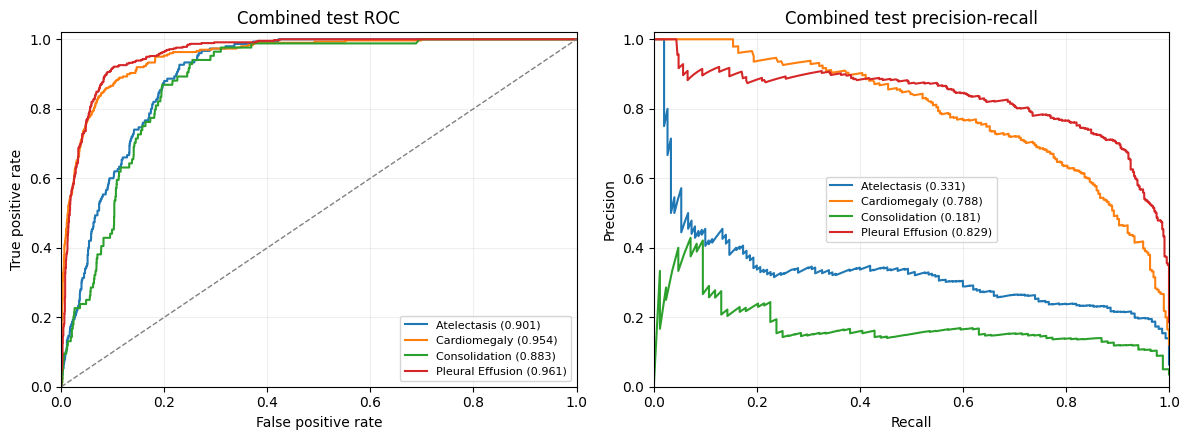

In [17]:
# Plot test ROC and precision-recall curves for observed labels
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for index, label in enumerate(LABELS):
    keep = observed[:, index] == 1
    y, score = truth[keep, index], probabilities[keep, index]
    if np.unique(y).size == 2:
        fpr, tpr, _ = roc_curve(y, score)
        axes[0].plot(fpr, tpr, label=f'{label} ({metrics.loc[label, "AUROC"]:.3f})')
    if y.sum():
        precision, recall, _ = precision_recall_curve(y, score)
        axes[1].plot(recall, precision, label=f'{label} ({metrics.loc[label, "AUPRC"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Combined test ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Combined test precision-recall')
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'test' / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


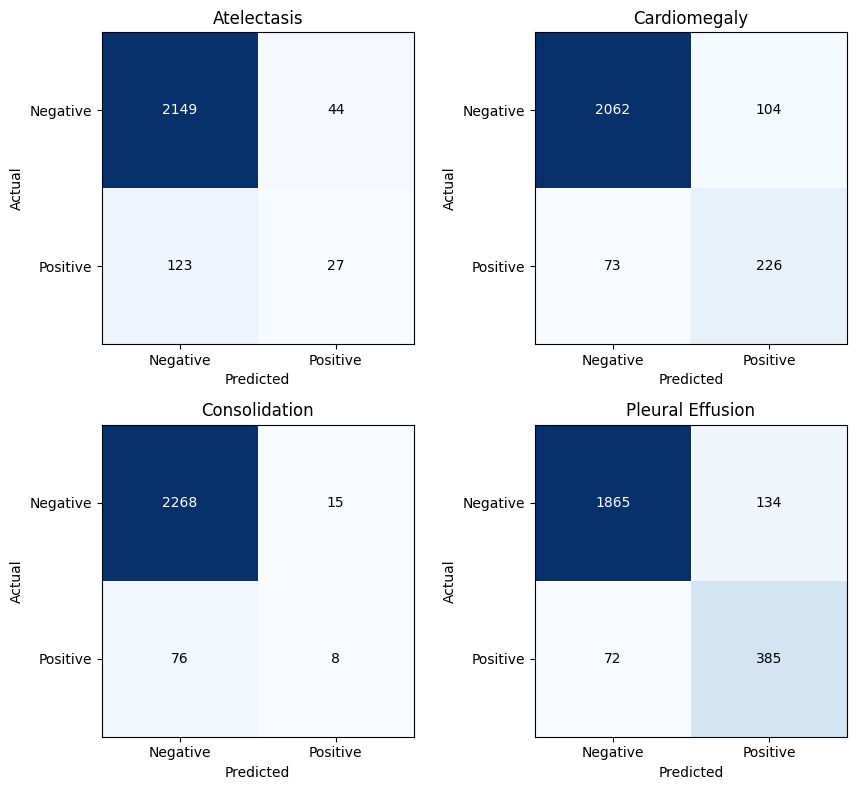

In [18]:
# Plot test confusion matrices at the fixed threshold
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for index, label in enumerate(LABELS):
    keep = observed[:, index] == 1
    matrix = confusion_matrix(truth[keep, index], probabilities[keep, index] >= THRESHOLD, labels=[0, 1])
    ax = axes.flat[index]
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
fig.tight_layout()
fig.savefig(RESULTS / 'test' / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


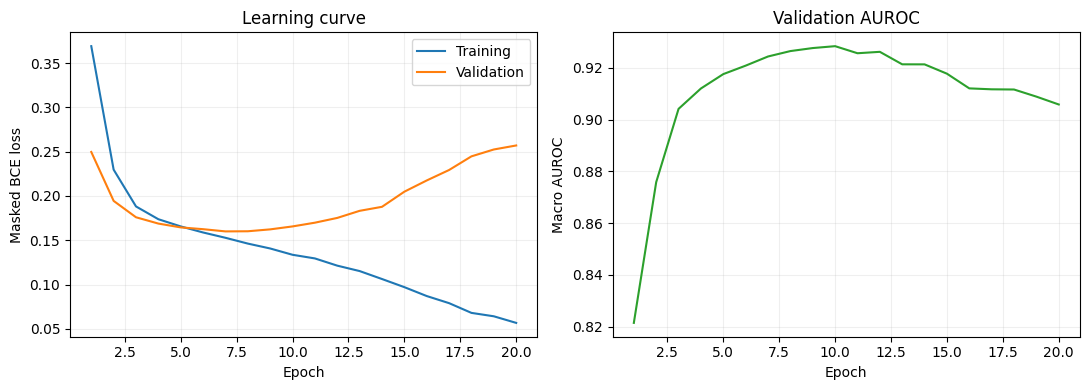

In [19]:
# Plot training and validation progress
history = pd.read_csv(RESULTS / 'finetuned' / 'history.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_loss, label='Training')
axes[0].plot(history.epoch, history.val_loss, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Masked BCE loss', title='Learning curve')
axes[0].legend()
axes[1].plot(history.epoch, history.val_AUROC, color='tab:green')
axes[1].set(xlabel='Epoch', ylabel='Macro AUROC', title='Validation AUROC')
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS / 'finetuned' / 'learning_curves.png', dpi=180)
plt.show()
plt.close(fig)


In [20]:
# Save timing and source information
timing = dict(training_seconds=train_seconds, test_inference_seconds=test_seconds,
              total_seconds=time.time() - START)
(RESULTS / 'timing.json').write_text(json.dumps(timing, indent=2))
(RESULTS / 'sources.txt').write_text('\n'.join([
    'https://www.nature.com/articles/s41746-025-02032-z',
    f'https://github.com/hustvl/EVA-X/tree/{REPO_COMMIT}',
    f'https://huggingface.co/MapleF/eva_x/tree/{HF_REVISION}',
]) + '\n')
print(f'Total time: {timing["total_seconds"]/60:.1f} minutes')
print('Results:', RESULTS)


Total time: 19.7 minutes
Results: /kaggle/working/eva_x_s_combined_results/seed14
